# Governor, inside the city

From `FINDINGS.md`:

> Xavier Becerra 280,594, Steve Hilton 50,784. Hilton’s share of the two-candidate vote is 15.3 percent.
>
> Precinct shares run from 6.8 percent to 15.4 percent to 25.4 percent. The higher shares are on the west side and in the south. Supervisor District 4 is 23.7 percent Hilton and District 11 is 20.9 percent. District 2 is 18.5 percent and District 7 is 17.4 percent. District 8 is 7.5 percent, District 9 is 9.8 percent, and District 5 is 9.9 percent. The spread from District 8 to District 4 is 16.2 points.
>
> Hilton’s share rises with the non-Hispanic Asian share of the precinct (r = 0.70) and with the foreign-born share (r = 0.54). It is lower where the non-Hispanic white share is higher (r = −0.45) and where the renter share is higher (r = −0.40).

Every number below is computed from the files in `source/`. Run the setup cell first, then the rest in order (Runtime → Run all). The last cell lists each number the memo section quotes next to the value computed here, and stops with an error if any differ.

In [1]:
# Run this cell first. It finds the sf-2026-drive folder (on Google Drive in Colab, or on
# this computer) and loads the shared code in notebooks/sf2026.py.
import subprocess
import sys
from pathlib import Path

try:
    import geopandas  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "geopandas"], check=True)

FOLDER_NAME = "sf-2026-drive"


def is_root(path: Path) -> bool:
    return (path / "source" / "precinct_results.csv").exists() and (path / "notebooks" / "sf2026.py").exists()


def find_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if is_root(candidate):
            return candidate
    try:
        from google.colab import drive
    except ImportError:
        raise FileNotFoundError("Open this notebook from inside the sf-2026-drive folder.")
    drive.mount("/content/drive")
    bases = [Path("/content/drive/MyDrive"), Path("/content/drive/Shareddrives")]
    for base in bases:
        if is_root(base / FOLDER_NAME):
            return base / FOLDER_NAME
    for base in bases:
        if base.exists():
            for helper in base.rglob("sf2026.py"):
                if is_root(helper.parent.parent):
                    return helper.parent.parent
    raise FileNotFoundError(
        f"Could not find the {FOLDER_NAME} folder on Drive. If you renamed it, set FOLDER_NAME above."
    )


ROOT = find_root()
sys.path.insert(0, str(ROOT / "notebooks"))
import pandas as pd
import sf2026 as sf

pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
data = sf.load(ROOT)
check = sf.MemoCheck()
print(f"Using the {ROOT.name} folder: {len(data)} precincts")

Using the sf-2026-drive folder: 514 precincts


## Citywide result

In [2]:
city = sf.citywide(data, "hilton", "becerra")
check.number("Becerra votes", 280594, city["becerra"], 0)
check.number("Hilton votes", 50784, city["hilton"], 0)
check.number("Hilton share of the two-candidate vote, percent", 15.3, city["share_pct"])
city

{'hilton': 50784,
 'becerra': 280594,
 'share_pct': 15.325097019114123,
 'margin': -229810}

## Precinct and supervisor-district geography

In [3]:
share, votes = sf.two_way(data, "hilton", "becerra")
enough = data["ballots"] >= sf.MIN_BALLOTS
districts = sf.by_district(data, "hilton", "becerra")
print("Precinct range, 10th / 50th / 90th percentile:", [round(v, 1) for v in sf.percentile_range(share, enough)])
districts.round(1).to_frame("Hilton share, percent")

Precinct range, 10th / 50th / 90th percentile: [np.float64(6.8), np.float64(15.4), np.float64(25.4)]


,"Hilton share, percent"
Supervisorial,
1,17.00
2,18.50
3,16.00
4,23.70
5,9.90
6,15.00
7,17.40
8,7.50
9,9.80


In [4]:
for name, memo, value in zip(["10th", "50th", "90th"], [6.8, 15.4, 25.4], sf.percentile_range(share, enough)):
    check.number(f"Precinct share, {name} percentile", memo, value)
check.number("Hilton share, District 4", 23.7, districts[4])
check.number("Hilton share, District 11", 20.9, districts[11])
check.number("Hilton share, District 2", 18.5, districts[2])
check.number("Hilton share, District 7", 17.4, districts[7])
check.number("Hilton share, District 8", 7.5, districts[8])
check.number("Hilton share, District 9", 9.8, districts[9])
check.number("Hilton share, District 5", 9.9, districts[5])
check.fact("Highest and lowest district", "District 4 and District 8",
           f"District {districts.idxmax()} and District {districts.idxmin()}",
           (districts.idxmax(), districts.idxmin()) == (4, 8))
check.number("Spread from District 8 to District 4, points", 16.2, districts.max() - districts.min())

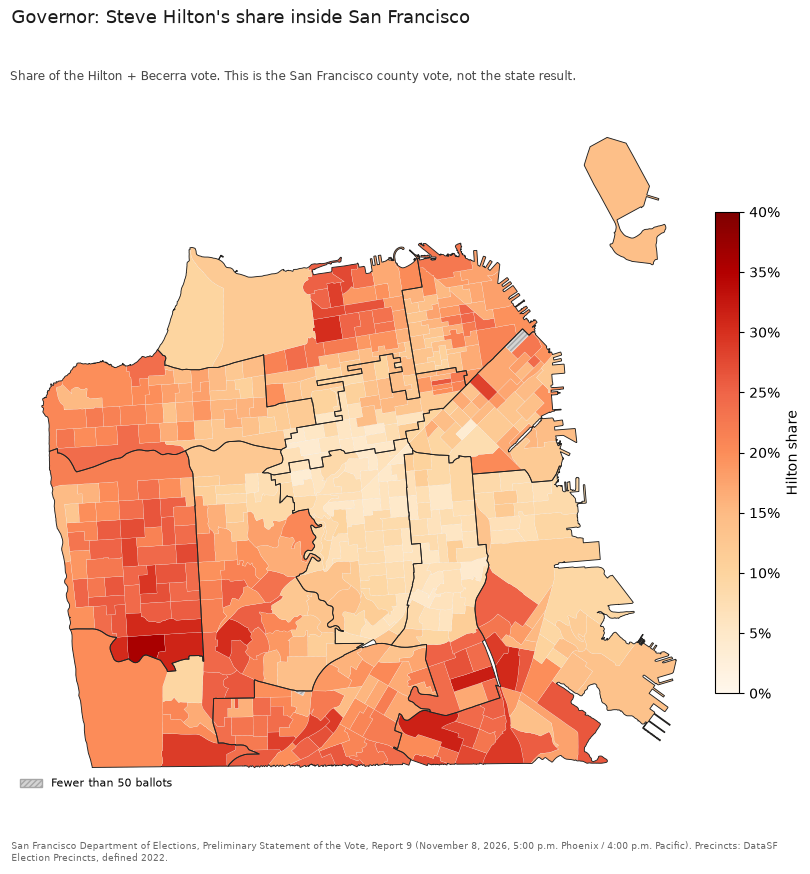

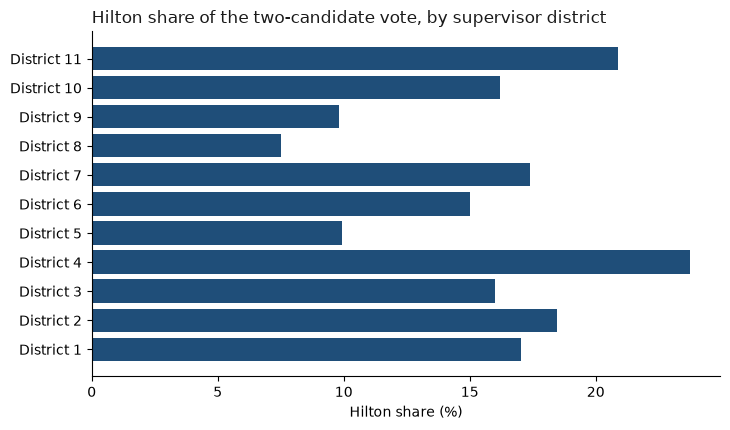

In [5]:
sf.rate_map(data, share, votes, "Governor: Steve Hilton's share inside San Francisco",
            "Share of the Hilton + Becerra vote. This is the San Francisco county vote, not the state result.",
            "Hilton share", cmap="OrRd", diverging=False, limits=(0.0, 0.40))
sf.district_bars(data.assign(weight=votes, share=share), "share", None,
                 "Hilton share of the two-candidate vote, by supervisor district", "Hilton share (%)", reference=None);

## Census comparison

,r
Non-Hispanic Asian,0.70
Non-Hispanic white,-0.45
Hispanic,-0.17
Bachelor's degree or higher,-0.38
Renters,-0.40
"Households at $150,000+",-0.15
Foreign born,0.54


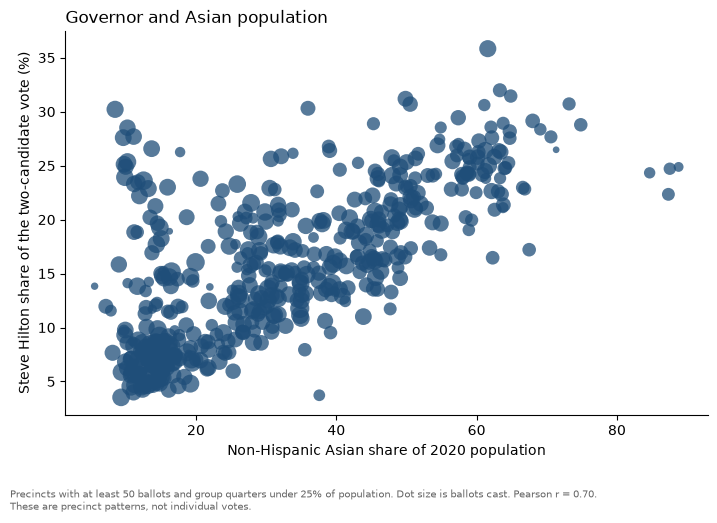

In [6]:
r = sf.census_correlations(data, share, sf.census_frame(data))
display(r.to_frame())
check.number("Correlation with Non-Hispanic Asian", 0.7, r["Non-Hispanic Asian"], 2)
check.number("Correlation with Foreign born", 0.54, r["Foreign born"], 2)
check.number("Correlation with Non-Hispanic white", -0.45, r["Non-Hispanic white"], 2)
check.number("Correlation with Renters", -0.4, r["Renters"], 2)
keep = sf.census_frame(data)
sf.census_scatter(data[keep].assign(share=share[keep]), "share", "nh_asian_share", None,
                  "Governor and Asian population", "Non-Hispanic Asian share of 2020 population",
                  "Steve Hilton share of the two-candidate vote (%)");

## Numbers the memo quotes

In [7]:
check.report();

,claim,memo,computed,matches
0,Becerra votes,"280,594","280,594",yes
1,Hilton votes,"50,784","50,784",yes
2,"Hilton share of the two-candidate vote, percent",15.3,15.3,yes
3,"Precinct share, 10th percentile",6.8,6.8,yes
4,"Precinct share, 50th percentile",15.4,15.4,yes
5,"Precinct share, 90th percentile",25.4,25.4,yes
6,"Hilton share, District 4",23.7,23.7,yes
7,"Hilton share, District 11",20.9,20.9,yes
8,"Hilton share, District 2",18.5,18.5,yes
9,"Hilton share, District 7",17.4,17.4,yes


All 19 numbers checked match the memo.
